# SI Fig. S5: binning and fitting for Expt 2, the three mismatch-repair strains

The same panel set as SI Fig. S4, one column per strain:

  S5a  reads per barcode at t0, and per virtual lineage after binning.
  S5b  the post-selection density against a slope -2 reference.
  S5c  the least-squares CCDF loss profiled over each of mu and alpha.
  S5d  the same for the Laplace-space fit.
  S5e  best-fit mu at each bin count, with 95% bootstrap intervals.
  S5f  best-fit alpha likewise.

Prints each fit next to the value cached in the fit-parameter pickle, which is
what Fig. 3 draws with, so the two can be checked against each other.

Runtime: ~6 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import time

import numpy as np
import matplotlib.pyplot as plt

from barfly import expt2, fitting, ld                                  # noqa: E402
from barfly.plotting import (STRAIN_LABELS, colorTable,
                               strain_bin_count_colour,
                               use_paper_style)                          # noqa: E402

OUTPUT_DIR = ROOT / "output"

N_REPLICATES_FIT = 500_000

# Three panels side by side, sized so a column matches the single-panel S4 figures.
PANEL_WIDTH = 2 / 3 * 0.8 * 16
PANEL_HEIGHT = 0.8 * 4

In [2]:
def plot_read_distributions(strains, counts_pre, counts_post, binned_pre,
                            bin_counts):
    """S5a and S5b: read distributions before and after selection, and after binning."""
    n_bin_counts = len(bin_counts)

    _, axes = plt.subplots(1, 3, figsize=(PANEL_WIDTH, PANEL_HEIGHT), sharey=True)
    for axis, strain in zip(axes, strains):
        counts = counts_pre[strain]
        hist_bins = np.logspace(np.log10(counts.min()), np.log10(counts.max()), 40)
        axis.hist(counts, bins=hist_bins, color=colorTable['k'])
        axis.set_xscale('log')
        axis.set_xlabel('counts per barcode at $t_0$')
        axis.set_title(STRAIN_LABELS[strain])
    axes[0].set_ylabel('number of barcodes')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figS05a_t0RawCounts.svg", bbox_inches="tight", dpi=300)
    plt.show()

    _, axes = plt.subplots(1, 3, figsize=(PANEL_WIDTH, PANEL_HEIGHT), sharey=True)
    for axis, strain in zip(axes, strains):
        nonzero = counts_post[strain][counts_post[strain] > 0]
        hist_bins = np.logspace(np.log10(nonzero.min()), np.log10(nonzero.max()), 50)
        density, edges, _ = axis.hist(nonzero, bins=hist_bins, density=True,
                                      color=colorTable['k'])
        # Slope -2 reference, anchored three-fold above the density at m = 1e5 so it
        # sits clear of the data rather than through it.
        centres = np.sqrt(edges[:-1] * edges[1:])
        anchor = density[np.argmin(np.abs(centres - 1e5))]
        reference_x = np.logspace(3, 5, 20)
        axis.plot(reference_x, 3 * anchor * 1e10 / reference_x ** 2, '--',
                  color='gray', linewidth=2, label=r'$\propto m^{-2}$')
        axis.set_xscale('log')
        axis.set_yscale('log')
        axis.set_xlabel('reads per barcode at $t_f$')
        axis.set_title(STRAIN_LABELS[strain])
    axes[0].set_ylabel('probability density')
    axes[0].legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figS05b_tfRawCounts.svg", bbox_inches="tight", dpi=300)
    plt.show()

    _, axes = plt.subplots(1, 3, figsize=(PANEL_WIDTH, PANEL_HEIGHT), sharey=True)
    for axis, strain in zip(axes, strains):
        all_binned = np.concatenate([binned_pre[strain][i] for i in range(n_bin_counts)])
        hist_bins = np.logspace(np.log10(all_binned[all_binned > 0].min()),
                                np.log10(all_binned.max()), 60)
        for i_k, n_bins in enumerate(bin_counts):
            values = binned_pre[strain][i_k]
            axis.hist(values, bins=hist_bins, histtype='step', linewidth=2,
                      weights=np.ones(len(values)) / len(values),
                      color=strain_bin_count_colour(strain, i_k, n_bin_counts),
                      label=f'k = {n_bins}')
        axis.set_xscale('log')
        axis.set_xlabel('counts per bin at $t_0$')
        axis.set_title(STRAIN_LABELS[strain])
        axis.legend(fontsize=8, ncol=2)
    axes[0].set_ylabel('fraction of bins')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figS05a_t0BinnedCounts.svg", bbox_inches="tight", dpi=300)
    plt.show()

In [3]:
def plot_loss_profiles(strains, losses, alpha_values, mu_values, filename):
    """S5c and S5d: loss profiled over each parameter, one column per strain."""
    _, axes = plt.subplots(2, 3, figsize=(4 / 3 * PANEL_WIDTH, 2 * PANEL_HEIGHT),
                           sharey='row')
    alpha_profiles = {strain: np.min(losses[strain], axis=0) for strain in strains}
    mu_profiles = {strain: np.min(losses[strain], axis=1) for strain in strains}

    for column, strain in enumerate(strains):
        axes[0, column].plot(alpha_values, alpha_profiles[strain], '.-',
                             color=colorTable['k'], markersize=10, linewidth=1.5)
        axes[0, column].set_xscale('log')
        axes[0, column].set_xlabel(r'$\alpha$')
        axes[0, column].set_title(STRAIN_LABELS[strain])
        axes[1, column].plot(mu_values, mu_profiles[strain], '.-',
                             color=colorTable['k'], markersize=10, linewidth=1.5)
        axes[1, column].set_xscale('log')
        axes[1, column].set_xticks([1e-8, 1e-7, 1e-6, 1e-5])
        axes[1, column].set_xlabel(r'$\mu$')

    # Each row spans up to the smallest of its three maxima, so a strain with a much
    # steeper loss surface does not flatten the other two.
    axes[0, 0].set_ylim(-0.03 * min(map(np.max, alpha_profiles.values())),
                        min(map(np.max, alpha_profiles.values())))
    axes[1, 0].set_ylim(-0.03 * min(map(np.max, mu_profiles.values())),
                        min(map(np.max, mu_profiles.values())))
    axes[0, 0].set_ylabel('sqr. err.')
    axes[1, 0].set_ylabel('sqr. err.')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, bbox_inches="tight", dpi=300)
    plt.show()

In [4]:
def plot_best_fits(strains, bin_counts, mu_ccdf, mu_laplace):
    """S5e and S5f: best-fit parameters against bin count, with bootstrap intervals.

    `boot` is indexed (replicate, strain, estimator, bin count, parameter): estimator
    0 is the CCDF fit and 1 the Laplace fit, bin-count row -1 is the global fit, and
    parameter 0 is mu, 1 is alpha.  Point estimates come from the same file as the
    intervals so that each interval brackets its own point.
    """
    bootstrap = np.load(ROOT / "data" / "bootstrap" / "20260801_expt2_bootstrap.npz")
    assert list(bootstrap['strains']) == list(strains)
    assert np.array_equal(bootstrap['kvec'], bin_counts)
    print(f"\nbootstrap: B = {int(bootstrap['B'])} replicates")

    for i, strain in enumerate(strains):
        print(f"  {strain}: global mu, CCDF fit {bootstrap['point'][i, 0, -1, 0]:.3e} "
              f"(script {mu_ccdf[strain][-1]:.3e}); Laplace fit "
              f"{bootstrap['point'][i, 1, -1, 0]:.3e} "
              f"(script {mu_laplace[strain][-1]:.3e})")

    positions = np.arange(len(bin_counts) + 1)
    labels = [str(n) for n in bin_counts] + ['global']
    panels = [("figS05e_bestFitMu.svg", r'best-fit $\mu$', (1e-7, 1e-5)),
              ("figS05f_bestFitAlpha.svg", r'best-fit $\alpha$', (0.1, 10))]
    for parameter, (filename, label, y_limits) in enumerate(panels):
        _, axes = plt.subplots(1, 3, figsize=(PANEL_WIDTH, PANEL_HEIGHT), sharey=True)
        for axis, (i, strain) in zip(axes, enumerate(strains)):
            for estimator, colour, name, offset in (
                    (0, '0.6', 'cumulative', -0.15),
                    (1, colorTable['k'], 'Laplace', +0.15)):
                point = bootstrap['point'][i, estimator, :, parameter]
                axis.errorbar(positions + offset, point,
                              yerr=fitting.percentile_interval(
                                  point,
                                  bootstrap['boot'][:, i, estimator, :, parameter]),
                              fmt='o', markersize=11, color=colour, ecolor=colour,
                              elinewidth=2, capsize=3, label=name)
            axis.set_yscale('log')
            axis.set_ylim(*y_limits)
            axis.set_xticks(positions)
            axis.set_xticklabels(labels, rotation=45, fontsize=9)
            axis.set_xlim(-0.6, len(bin_counts) + 0.6)
            axis.set_xlabel('k bins')
            axis.set_title(STRAIN_LABELS[strain])
        axes[0].set_ylabel(label)
        axes[0].legend(fontsize=9)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / filename, bbox_inches="tight", dpi=300)
        plt.show()

yKH88: 65789 barcodes pass the cutoffs
yFR1: 86826 barcodes pass the cutoffs
yFR2: 43522 barcodes pass the cutoffs


yKH88: total mutants at alpha = 1 = 6000


yFR1: total mutants at alpha = 1 = 32695


yFR2: total mutants at alpha = 1 = 214349
yKH88: CCDF scored up to 104 mutants
yFR1: CCDF scored up to 635 mutants
yFR2: CCDF scored up to 5841 mutants


yKH88: CCDF fit mu = 3.393e-07, alpha = 5.204 (cached: mu = 2.560e-07, alpha = 3.607) [17s]


yKH88: Laplace fit mu = 4.329e-07, alpha = 7.137 (cached: mu = 4.329e-07)


yFR1: CCDF fit mu = 1.207e-06, alpha = 4.076 (cached: mu = 1.207e-06, alpha = 4.076) [17s]


yFR1: Laplace fit mu = 1.233e-06, alpha = 4.142 (cached: mu = 1.233e-06)


yFR2: CCDF fit mu = 2.812e-06, alpha = 1.733 (cached: mu = 2.812e-06, alpha = 1.733) [16s]


yFR2: Laplace fit mu = 2.154e-06, alpha = 1.163 (cached: mu = 2.154e-06)


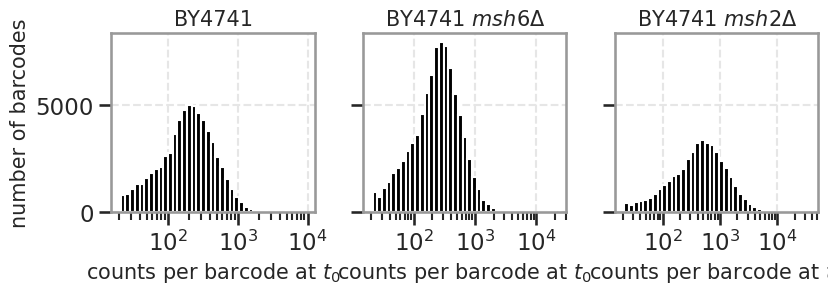

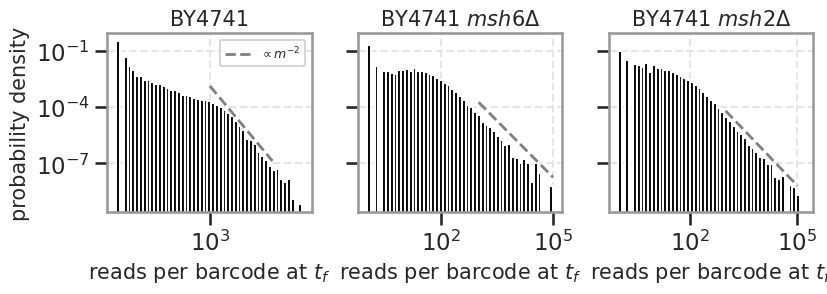

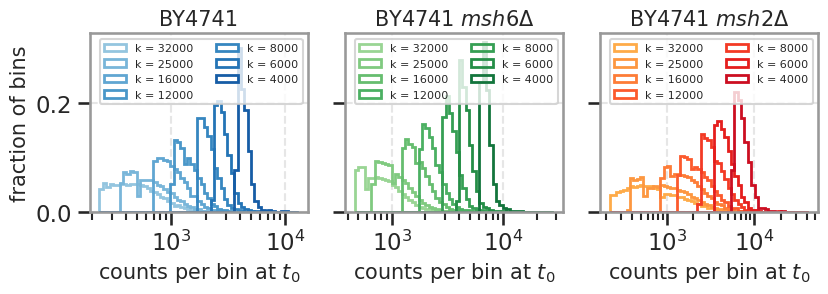

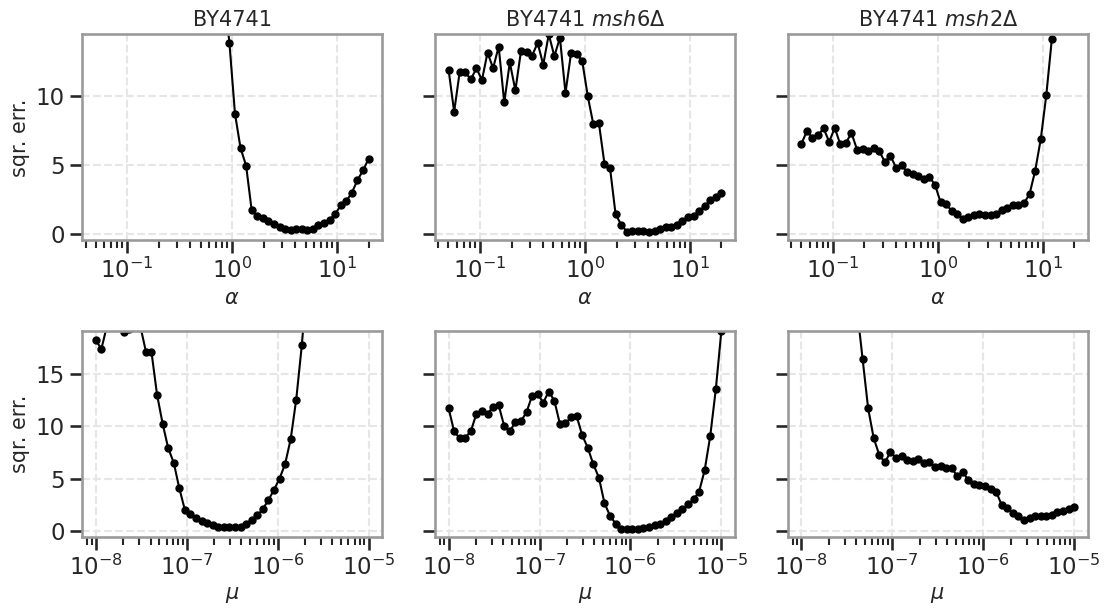

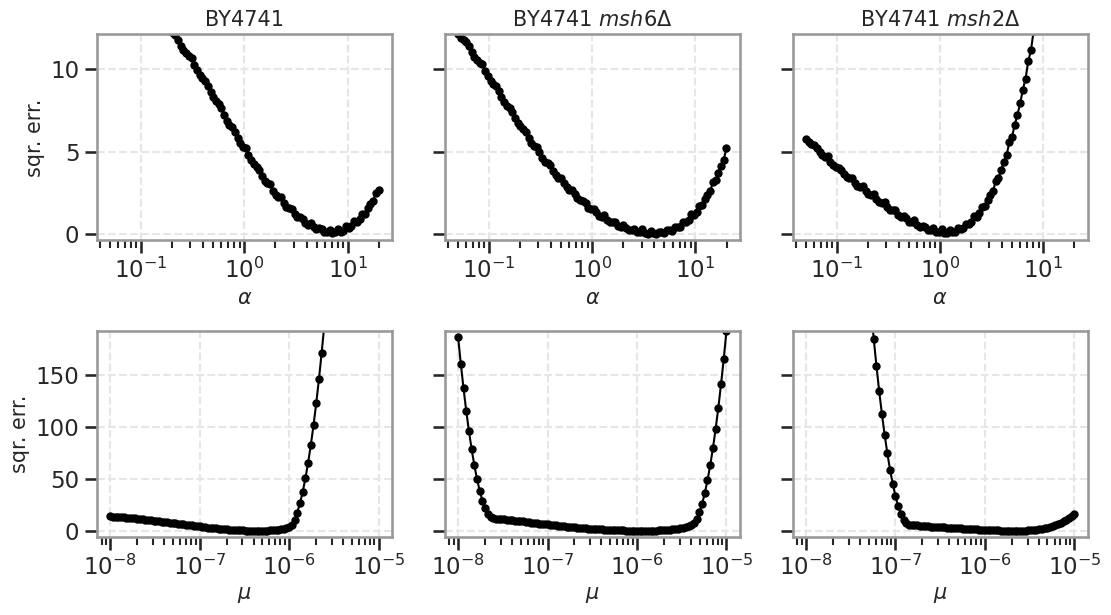


bootstrap: B = 10000 replicates
  yKH88: global mu, CCDF fit 2.852e-07 (script 3.393e-07); Laplace fit 4.331e-07 (script 4.329e-07)
  yFR1: global mu, CCDF fit 9.791e-07 (script 1.207e-06); Laplace fit 1.148e-06 (script 1.233e-06)
  yFR2: global mu, CCDF fit 2.867e-06 (script 2.812e-06); Laplace fit 2.044e-06 (script 2.154e-06)


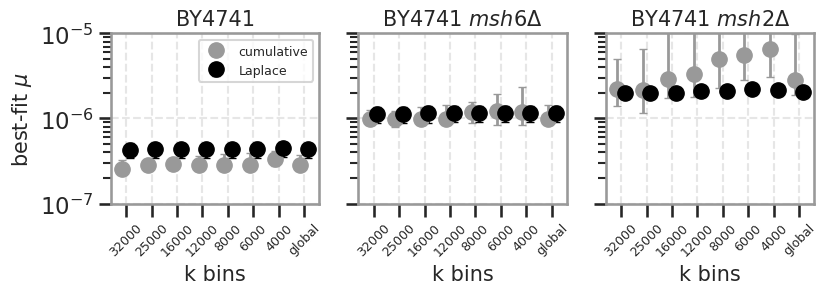

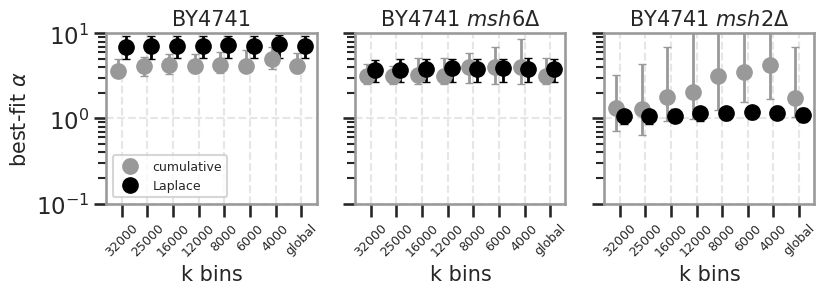


Done in 62s.


In [5]:
started = time.time()
use_paper_style()
OUTPUT_DIR.mkdir(exist_ok=True)

params = expt2.load_params()
strains, bin_counts = params["strains"], params["kvec"]
counts_pre, counts_post, reads_post, _ = expt2.load_counts(params)
for strain in strains:
    print(f"{strain}: {len(counts_pre[strain])} barcodes pass the cutoffs")

# Combine barcodes into virtual lineages at each bin count, per strain, then
# convert each lineage's reads to a mutant number by SI Eq. 10 at alpha = 1.  The
# plated mutant count differs by two orders of magnitude between wildtype and msh2D.
binned_pre, binned_post, mutants, totals = {}, {}, {}, {}
for strain in strains:
    binned_pre[strain], binned_post[strain], mutants[strain] = {}, {}, {}
    totals[strain] = ((np.sum(counts_post[strain]) / reads_post[strain])
                      * params["CFU"][strain])
    for i_k, n_bins in enumerate(bin_counts):
        _, pre, post = ld.bin_barcodes(counts_pre[strain], counts_post[strain], n_bins)
        binned_pre[strain][i_k] = pre
        binned_post[strain][i_k] = post
        mutants[strain][i_k] = totals[strain] * post / np.sum(post)
    print(f"{strain}: total mutants at alpha = 1 = {totals[strain]:.0f}")

thresholds = {}
for strain in strains:
    thresholds[strain], largest = fitting.ccdf_thresholds(mutants[strain])
    print(f"{strain}: CCDF scored up to {largest:.0f} mutants")

mu_values = np.logspace(-8, -5, 50)
alpha_values = np.logspace(-1.3, 1.3, 50)
mu_values_laplace = np.logspace(-8, -5, 100)
alpha_values_laplace = np.logspace(-1.3, 1.3, 100)

ccdf_losses, laplace_losses = {}, {}
mu_ccdf, alpha_ccdf, mu_laplace, alpha_laplace = {}, {}, {}, {}
for strain in strains:
    step = time.time()
    simulations = fitting.simulate_over_mu(
        mu_values, bin_counts, params["totalN"][strain],
        n_replicates=N_REPLICATES_FIT, label=strain)
    loss = fitting.ccdf_loss(mutants[strain], simulations, mu_values,
                             alpha_values, thresholds[strain])
    ccdf_losses[strain] = loss.sum(axis=0)
    mu_ccdf[strain], alpha_ccdf[strain] = fitting.best_fit_per_bin_count(
        loss, mu_values, alpha_values)
    print(f"{strain}: CCDF fit mu = {mu_ccdf[strain][-1]:.3e}, "
          f"alpha = {alpha_ccdf[strain][-1]:.3f} "
          f"(cached: mu = {params['best_mu'][strain]:.3e}, "
          f"alpha = {params['best_alpha'][strain]:.3f}) [{time.time() - step:.0f}s]")

    loss = fitting.laplace_loss(mutants[strain], bin_counts, mu_values_laplace,
                                alpha_values_laplace, params["totalN"][strain])
    laplace_losses[strain] = loss.sum(axis=0)
    mu_laplace[strain], alpha_laplace[strain] = fitting.best_fit_per_bin_count(
        loss, mu_values_laplace, alpha_values_laplace)
    print(f"{strain}: Laplace fit mu = {mu_laplace[strain][-1]:.3e}, "
          f"alpha = {alpha_laplace[strain][-1]:.3f} "
          f"(cached: mu = {params['lap_best_mu'][strain]:.3e})")


plot_read_distributions(strains, counts_pre, counts_post, binned_pre, bin_counts)
plot_loss_profiles(strains, ccdf_losses, alpha_values, mu_values,
                   "figS05c_lossProfilesLS.svg")
plot_loss_profiles(strains, laplace_losses, alpha_values_laplace,
                   mu_values_laplace, "figS05d_lossProfilesLaplace.svg")
plot_best_fits(strains, bin_counts, mu_ccdf, mu_laplace)

print(f"\nDone in {time.time() - started:.0f}s.")

In [6]:
sys.path.insert(0, str(ROOT))